In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Day 25: Student Performance Prediction System")
print("Libraries imported successfully!")

Day 25: Student Performance Prediction System
Libraries imported successfully!


In [2]:
data_path = Path.cwd() / "day23_student_performance_predictions.csv"

if data_path.exists():
    df = pd.read_csv(data_path)
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    print("Dataset not found!")
    print("Current folder:", Path.cwd())
    print("Please keep the CSV file in the notebook folder.")

Dataset loaded successfully!
Dataset shape: (1, 5)


,study_hours,attendance,previous_score,assignments_completed,predicted_performance
0,6,90,78,9,High


In [3]:
print("Dataset Information")
print("-" * 40)

print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset Information
----------------------------------------
Rows and columns: (1, 5)

Column names:
['study_hours', 'attendance', 'previous_score', 'assignments_completed', 'predicted_performance']

Data types:
study_hours              int64
attendance               int64
previous_score           int64
assignments_completed    int64
predicted_performance      str
dtype: object

Missing values:
study_hours              0
attendance               0
previous_score           0
assignments_completed    0
predicted_performance    0
dtype: int64

Duplicate rows: 0


Predicted Performance Distribution:
predicted_performance
High    1
Name: count, dtype: int64


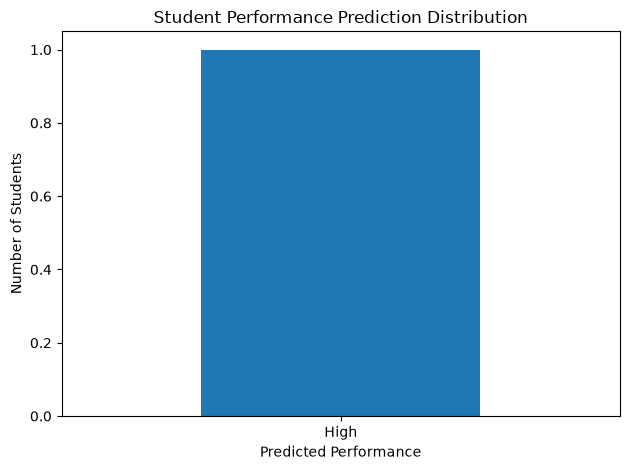

In [4]:
if "predicted_performance" in df.columns:
    print("Predicted Performance Distribution:")
    print(df["predicted_performance"].value_counts())

    df["predicted_performance"].value_counts().plot(
        kind="bar",
        title="Student Performance Prediction Distribution"
    )

    plt.xlabel("Predicted Performance")
    plt.ylabel("Number of Students")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("predicted_performance column not found.")

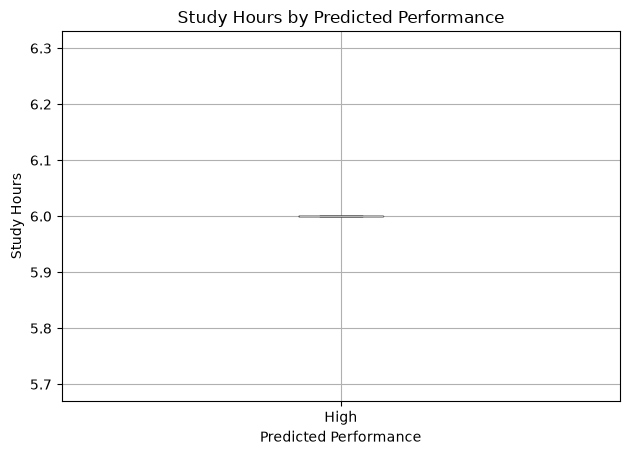

In [5]:
if {"study_hours", "predicted_performance"}.issubset(df.columns):
    df.boxplot(
        column="study_hours",
        by="predicted_performance"
    )

    plt.title("Study Hours by Predicted Performance")
    plt.suptitle("")
    plt.xlabel("Predicted Performance")
    plt.ylabel("Study Hours")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found.")

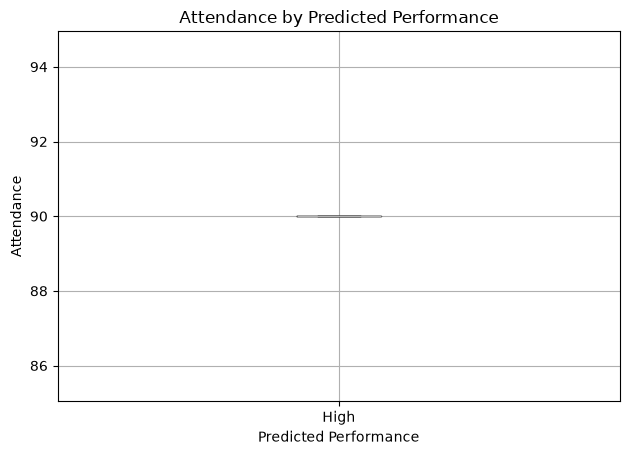

In [6]:
if {"attendance", "predicted_performance"}.issubset(df.columns):
    df.boxplot(
        column="attendance",
        by="predicted_performance"
    )

    plt.title("Attendance by Predicted Performance")
    plt.suptitle("")
    plt.xlabel("Predicted Performance")
    plt.ylabel("Attendance")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found.")

Correlation Matrix:


,study_hours,attendance,previous_score,assignments_completed
study_hours,NaN,NaN,NaN,NaN
attendance,NaN,NaN,NaN,NaN
previous_score,NaN,NaN,NaN,NaN
assignments_completed,NaN,NaN,NaN,NaN


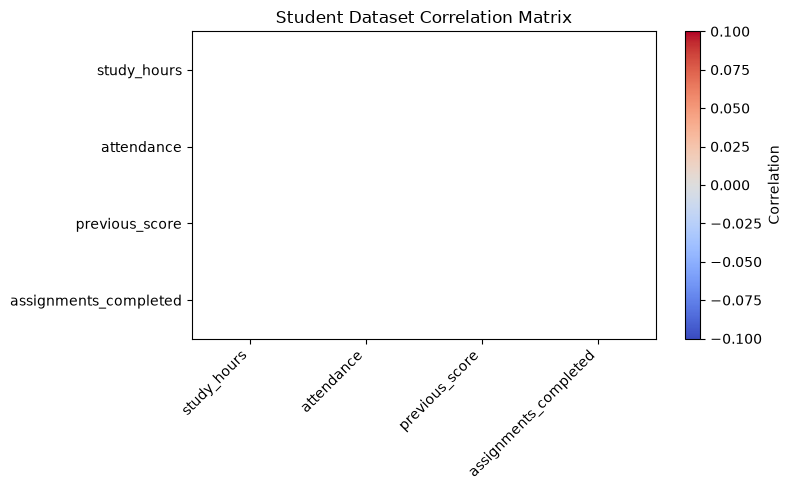

In [7]:
numeric_df = df.select_dtypes(include=np.number)

if not numeric_df.empty:
    correlation = numeric_df.corr()

    print("Correlation Matrix:")
    display(correlation)

    plt.figure(figsize=(8, 5))
    plt.imshow(correlation, cmap="coolwarm", aspect="auto")
    plt.colorbar(label="Correlation")

    plt.xticks(
        range(len(correlation.columns)),
        correlation.columns,
        rotation=45,
        ha="right"
    )
    plt.yticks(range(len(correlation.columns)), correlation.columns)

    plt.title("Student Dataset Correlation Matrix")
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns available.")

In [8]:
output_dir = Path.cwd()

summary = df.describe(include="all").transpose()
summary.to_csv(output_dir / "day25_prediction_summary.csv")

df.isnull().sum().to_csv(
    output_dir / "day25_dataset_quality.csv",
    header=["missing_values"]
)

if not numeric_df.empty:
    numeric_df.corr().to_csv(
        output_dir / "day25_correlation_matrix.csv"
    )

print("Analysis results saved successfully!")
print("Output folder:", output_dir)

Analysis results saved successfully!
Output folder: c:\Internship_project\Data


In [9]:
report = f"""
DAY 25 PROJECT REPORT
Project Name: Student Performance Prediction System

Dataset rows: {df.shape[0]}
Dataset columns: {df.shape[1]}

Available columns:
{df.columns.tolist()}

Missing values:
{df.isnull().sum().to_string()}

Duplicate rows: {df.duplicated().sum()}

Note:
This dataset contains predicted performance labels.
Actual ground-truth labels are not available in the
provided columns, so model accuracy and other
classification evaluation metrics cannot yet be verified.
"""

report_path = output_dir / "day25_student_performance_analysis_report.txt"
report_path.write_text(report, encoding="utf-8")

print(report)
print("Report saved:", report_path.name)


DAY 25 PROJECT REPORT
Project Name: Student Performance Prediction System

Dataset rows: 1
Dataset columns: 5

Available columns:
['study_hours', 'attendance', 'previous_score', 'assignments_completed', 'predicted_performance']

Missing values:
study_hours              0
attendance               0
previous_score           0
assignments_completed    0
predicted_performance    0

Duplicate rows: 0

Note:
This dataset contains predicted performance labels.
Actual ground-truth labels are not available in the
provided columns, so model accuracy and other
classification evaluation metrics cannot yet be verified.

Report saved: day25_student_performance_analysis_report.txt


In [10]:
files_to_check = [
    "day25_prediction_summary.csv",
    "day25_dataset_quality.csv",
    "day25_correlation_matrix.csv",
    "day25_student_performance_analysis_report.txt"
]

print("DAY 25 OUTPUT VERIFICATION")
print("-" * 40)

for filename in files_to_check:
    path = output_dir / filename
    if path.exists():
        print(f"[OK] {filename}")
    else:
        print(f"[MISSING] {filename}")

print("\nDay 25 analysis completed!")

DAY 25 OUTPUT VERIFICATION
----------------------------------------
[OK] day25_prediction_summary.csv
[OK] day25_dataset_quality.csv
[OK] day25_correlation_matrix.csv
[OK] day25_student_performance_analysis_report.txt

Day 25 analysis completed!
